<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">Timestamped Soccer Asia &amp; Africa: 7 Top Flights — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The key figures of the listing, recomputed from the files of the full product:
17,329 matches from the top division of 7 countries (Japan, South Korea, China, Saudi Arabia, Morocco,
Algeria, Tunisia), 31,454,431 timestamped quotes from 5 named bookmakers incl. Pinnacle,
944,160 snapshots from 37 more bookmakers, 2016–2026.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing,
recomputes it from the files and prints **PASS** or **FAIL**. The expected values are written once, in plain
sight, in the `CLAIMS` cell; everything else is read from the data.

⚽ **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/gxvqou?utm_source=github&utm_medium=notebook&utm_campaign=asia_africa_premium&utm_content=notebook_top)** · free 20-match sample: same files, same columns.

## 0 · Setup

In [1]:
import os, glob, hashlib, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)

def find_root():
    """Folder of the full product: the AsiaAfrica_Matches.csv with the most rows wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("AA_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += glob.glob(os.path.join(base, "**", "AsiaAfrica_Matches.csv"), recursive=True)
    if not hits:
        raise FileNotFoundError("AsiaAfrica_Matches.csv not found: attach the dataset to this notebook")
    return os.path.dirname(max(hits, key=os.path.getsize))

ROOT = find_root()
print("Product folder:", ROOT)

def table_files(prefix):
    """The 7 per-league files of a table, wherever they sit under the product folder:
    .csv.gz as shipped, or .csv when the hosting platform stores them decompressed."""
    for ext in (".csv.gz", ".csv"):
        # files only: Kaggle stores each decompressed .csv.gz as a folder "X.csv" that holds the file "X.csv"
        hits = sorted(p for p in glob.glob(os.path.join(ROOT, "**", prefix + "*" + ext), recursive=True)
                      if os.path.isfile(p))
        if hits:
            return hits
    return []

def stem(path):
    """File name without folder or extension: the key of the MANIFEST row counts."""
    b = os.path.basename(path)
    return b[:-7] if b.endswith(".csv.gz") else b.rsplit(".", 1)[0]

FILES = {t: table_files(p) for t, p in (("odds", "AsiaAfrica_Odds_Timestamped_"),
                                        ("snapshots", "AsiaAfrica_Bookmaker_Snapshots_"),
                                        ("events", "AsiaAfrica_Events_"), ("lineups", "AsiaAfrica_Lineups_"),
                                        ("minute_stats", "AsiaAfrica_Minute_Stats_"))}
for t, fs in FILES.items():
    kinds = sorted({".csv.gz" if f.endswith(".gz") else ".csv" for f in fs}) or ["none found"]
    print(f"{t:13} {len(fs):>2} files  ({', '.join(kinds)})")
assert all(len(fs) == 7 for fs in FILES.values()), \
    "each table should have 7 files, one per league: is the dataset fully processed on this platform?"

# Olivier Sports Data dark signature. HDA = home / draw / away, checked for colour-blind and normal-vision
# separation on this background.
BG, FG, FG2, GRID, CYAN = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff"
HDA = {"Home": "#00a3cc", "Draw": "#c98500", "Away": "#d55181"}
BOOK_COLOR = {"Bet365": "#00d4ff", "Pinnacle": "#f0c75e", "Unibet": "#7bd88f", "Betfair": "#d55181", "Betsson": "#b59cff"}
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": FG2, "xtick.color": FG2, "ytick.color": FG2,
    "text.color": FG, "axes.titlecolor": FG, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5,
    "legend.frameon": False, "figure.dpi": 110,
})

RESULTS = []
def check(claim, ok, detail=""):
    RESULTS.append((claim, bool(ok), detail))
    print(("PASS  " if ok else "FAIL  ") + claim + (f"   [{detail}]" if detail else ""))

def epoch(s):
    """ISO 8601 UTC 'YYYY-MM-DDTHH:MM:SSZ' -> Unix seconds (NaN when empty)."""
    t = pd.to_datetime(s, format="%Y-%m-%dT%H:%M:%SZ", utc=True, errors="coerce")
    return (t - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()

BOOKS = ["Bet365", "Pinnacle", "Unibet", "Betfair", "Betsson"]
KNOCKOUT = ["Play-In", "Round of 16", "Quarter-finals", "Semi-finals", "Third Place", "Final", "Play-Offs"]
SHOOTOUT_GROUPS = [("JPN", "2026", "100 Year Vision League", "Group Stage")]   # a draw after 90 minutes goes to penalties

Product folder: ./Timestamped_Soccer_Asia_Africa_Premium_2016-2026
odds           7 files  (.csv.gz)
snapshots      7 files  (.csv.gz)
events         7 files  (.csv.gz)
lineups        7 files  (.csv.gz)
minute_stats   7 files  (.csv.gz)


## 1 · The claims

Copied from the listing and the README. Nothing below is adjusted to fit: if the files disagree, the cell prints FAIL.

In [2]:
CLAIMS = {
    'matches': 17_329,
    'leagues': 7,
    'league_seasons': 78,
    'editions': 78,
    'first_kickoff_on': '2016-08-28',
    'last_kickoff_before': '2026-10-01T00:00:00Z',
    'matches_per_league': {
        'ALG': 2_536, 'CHN': 2_341, 'JPN': 3_324, 'KOR': 2_230, 'KSA': 2_535, 'MAR': 2_403, 'TUN': 1_960,
    },
    'knockout': {
        'matches': 94, 'single': 16, 'two_legged_ties': 39, 'third_matches': 0, 'lone_second_legs': 0,
        'lone_first_legs': 0,
    },
    'extra_time': 9,
    'penalty_shootouts': 56,
    'group_stage_shootouts': 51,
    'knockout_shootouts_without_extra_time': 1,
    'neutral_venue': {'neutral': 0, 'home_country': 16_315, 'unknown': 1_014},
    'round_filled': 17_088,
    'quotes': 31_454_431,
    'in_play': 24_380_334,
    'pre_match': 7_074_097,
    'quotes_per_book': {
        'Bet365': 22_664_448, 'Pinnacle': 1_295_298, 'Unibet': 2_075_264, 'Betfair': 4_649_647, 'Betsson': 769_774,
    },
    'in_play_score_and_clock': {
        'Bet365': 20_365_648, 'Pinnacle': 25, 'Unibet': 1_962_849, 'Betfair': 230_094, 'Betsson': 492_525,
    },
    'pre_match_with_minute': {'Bet365': 463, 'Pinnacle': 0, 'Unibet': 0, 'Betfair': 0, 'Betsson': 0},
    'ft_1x2_close_per_book': {
        'Bet365': 16_736, 'Pinnacle': 12_974, 'Unibet': 15_212, 'Betfair': 3_384, 'Betsson': 6_812,
    },
    'median_close_gap': {
        'Bet365': '22 min', 'Betfair': '6 min', 'Betsson': '10 min', 'Pinnacle': '4 min', 'Unibet': '1.8 h',
    },
    'coverage_from': {
        'Bet365': '2016-09-08', 'Pinnacle': '2018-09-27', 'Unibet': '2017-04-15', 'Betfair': '2023-11-03',
        'Betsson': '2022-07-03', 'Minute_Stats': '2017-06-10', 'Events': '2016-08-28',
    },
    'coverage_gaps': {
        'Bet365': [], 'Pinnacle': [['2023-09', '2023-11'], ['2026-07', '2026-08']],
        'Unibet': [['2026-07', '2026-08']], 'Betfair': [['2024-11', '2025-08'], ['2026-07', '2026-08']],
        'Betsson': [['2026-07', '2026-08']], 'Minute_Stats': [['2018-01', '2019-09'], ['2026-07', '2026-07']],
        'Events': [],
    },
    'coverage_stops': {
        'Bet365': {}, 'Pinnacle': {}, 'Unibet': {}, 'Betfair': {}, 'Betsson': {}, 'Minute_Stats': {}, 'Events': {},
    },
    'matches_with_bet365_clock': 16_216,
    'start_5_to_30_min_late': 536,
    'source_kickoff_over_3h_late': 4,
    'source_kickoff_over_3h_early': 5,
    'snapshots': 944_160,
    'snapshot_books': 37,
    'team_stats': 34_658,
    'lineups': 325_517,
    'events': 390_628,
    'minute_stats': 4_287_131,
    'minute_stats_time': {'from': '2021-05-10', 'matches_without': 3_127, 'rows_without': 1_131_216},
    'example_in_play_bet365_1x2': 157,
    'example_quotes_all_books': 1_858,
    'first_close_per_market': {
        'Bet365': {'FT_1X2': '2016-09-08', 'FT_Asian_Handicap': '2016-09-08', 'FT_Total_Goals': '2016-09-08', 'FT_Total_Corners': '2019-10-13', 'HT_1X2': '2018-01-11', 'HT_Asian_Handicap': '2019-10-13', 'HT_Total_Goals': '2016-12-10', 'HT_Total_Corners': '2016-12-10'},
        'Pinnacle': {'FT_1X2': '2018-09-27', 'FT_Asian_Handicap': '2023-06-23', 'FT_Total_Goals': '2018-09-27'},
        'Unibet': {'FT_1X2': '2017-04-15', 'FT_Total_Goals': '2017-04-15'}, 'Betfair': {'FT_1X2': '2023-11-03'},
        'Betsson': {'FT_1X2': '2022-07-03', 'FT_Total_Goals': '2022-07-03'},
    },
    'snapshot_matches': 16_644,
    'snapshot_books_per_match': 13.8,
    'lineups_share': {'ALG': 0, 'CHN': 100, 'JPN': 100, 'KOR': 67, 'KSA': 48, 'MAR': 0, 'TUN': 0},
    'event_types': 13,
    'team_stat_metrics': 29,
    'removed_ids': ['84224', '103003', '103004', '103005', '195208', '198147', '301880', '508157', '575622', '647567', '694747', '756223', '868846', '1083990', '1605388', '1621479', '1916505', '2024316', '2083345', '3010330', '3271227', '3271229', '4856615', '6680041', '7475112', '7475113', '7526930', '7883993', '9099965', '9099966', '9191887'],
    'kept_decided_ids': ['5086517', '6527818', '8073819', '8686780'],
}

## 2 · Every file is the one that was shipped

`MANIFEST.csv` lists each file with its row count and SHA-256 fingerprint. Recomputing the fingerprints proves
that nothing was altered between the build and this notebook.

In [3]:
man = pd.read_csv(os.path.join(ROOT, "MANIFEST.csv"), dtype=str)
located = {}
for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True):
    if os.path.isfile(p):
        located.setdefault(os.path.basename(p), p)
t0, missing, altered, decompressed, hashed = time.time(), [], [], [], 0
for f, h in zip(man["File"], man["SHA256"]):
    p = os.path.join(ROOT, *f.split("/"))
    if not os.path.exists(p):
        p = located.get(os.path.basename(f))
    if p is None and f.endswith(".gz") and os.path.basename(f)[:-3] in located:
        decompressed.append(f); continue
    if p is None:
        missing.append(f); continue
    d = hashlib.sha256()
    with open(p, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 22), b""):
            d.update(block)
    hashed += os.path.getsize(p)
    if d.hexdigest() != h:
        altered.append(f)
print(f"{len(man)} files, {hashed / 1e9:.2f} GB hashed in {time.time() - t0:.1f} s")
check(f"all {len(man)} files present", not missing, ", ".join(missing[:5]))
check("every SHA-256 matches the MANIFEST" + (" (files kept compressed)" if decompressed else ""),
      not altered and not missing, ", ".join(altered[:5]))
if decompressed:
    print(f"Note: {len(decompressed)} .csv.gz files are stored decompressed (.csv) on this platform, so their compressed "
          "fingerprint cannot match. Their row counts are checked file by file against the MANIFEST below.")
man["Rows"] = pd.to_numeric(man["Rows"], errors="coerce")
ROWS = {stem(f): int(r) for f, r in zip(man["File"], man["Rows"]) if pd.notna(r)}
groups = man.assign(Table=man["File"].str.replace(r"(_[A-Z]{3})?\.(csv\.gz|csv|xlsx|md)$", "", regex=True)
                                   .str.replace(r"^.*/", "", regex=True))
groups.groupby("Table").agg(files=("File", "size"), rows=("Rows", "sum")).astype(int)

44 files, 0.40 GB hashed in 0.4 s
PASS  all 44 files present
PASS  every SHA-256 matches the MANIFEST


,files,rows
Table,,
AsiaAfrica_Bookmaker_Snapshots,7,944160
AsiaAfrica_Coverage,2,78
AsiaAfrica_Events,7,390628
AsiaAfrica_Lineups,7,325517
AsiaAfrica_Matches,2,17329
AsiaAfrica_Minute_Stats,7,4287131
AsiaAfrica_Odds_Timestamped,7,31454431
AsiaAfrica_Opening_Closing_Odds,2,17329
AsiaAfrica_Team_Stats,2,34658


## 3 · Matches

In [4]:
M = pd.read_csv(os.path.join(ROOT, "AsiaAfrica_Matches.csv"), low_memory=False,
                dtype={"Match_ID": str, "Home_Team_ID": str, "Away_Team_ID": str, "Season": str,
                       "Home_Formation": str, "Away_Formation": str})
ORDER = sorted(M["Competition_Code"].unique())
check(f"{CLAIMS['matches']:,} matches", len(M) == CLAIMS["matches"], f"{len(M):,}")
check("Match_ID is unique", M["Match_ID"].is_unique)
check(f"none of the {len(CLAIMS['removed_ids'])} removed source events is in the files; the "
      f"{len(CLAIMS['kept_decided_ids'])} matches decided by the federation and kept are",
      not set(CLAIMS["removed_ids"]) & set(M["Match_ID"]) and set(CLAIMS["kept_decided_ids"]) <= set(M["Match_ID"]),
      ", ".join(sorted(set(CLAIMS["removed_ids"]) & set(M["Match_ID"]))))
seasons = M[["Competition_Code", "Season"]].drop_duplicates()
editions = M.assign(T=M["Tournament"].fillna(""))[["Competition_Code", "Season", "T"]].drop_duplicates()
check(f"{CLAIMS['leagues']} top flights (club football, division 1), {CLAIMS['league_seasons']} league-seasons, "
      f"{CLAIMS['editions']} editions (Japan's 2026 special tournament counts as its own season)",
      M["Competition_Code"].nunique() == CLAIMS["leagues"] and len(seasons) == CLAIMS["league_seasons"]
      and len(editions) == CLAIMS["editions"] and (M["Division"] == 1).all() and (M["Team_Type"] == "Club").all(),
      f"{M['Competition_Code'].nunique()} / {len(seasons)} / {len(editions)}")
per_league = M["Competition_Code"].value_counts().to_dict()
check("matches per league, as listed", per_league == CLAIMS["matches_per_league"],
      ", ".join(f"{c} {per_league.get(c, 0)}" for c in ORDER if per_league.get(c, 0) != CLAIMS["matches_per_league"].get(c)))
check(f"first kickoff on {CLAIMS['first_kickoff_on']}, last before {CLAIMS['last_kickoff_before'][:10]}",
      M["Kickoff_UTC"].min().startswith(CLAIMS["first_kickoff_on"]) and M["Kickoff_UTC"].max() < CLAIMS["last_kickoff_before"],
      f"{M['Kickoff_UTC'].min()} to {M['Kickoff_UTC'].max()}")
check("Season reads 2016/17 (two calendar years) or 2019 (one)", M["Season"].str.fullmatch(r"\d{4}(/\d{2})?").all(),
      ", ".join(sorted(M["Season"].unique())[:4]) + "...")
ko = M["Stage"].isin(KNOCKOUT)
check("Leg only in knockout stages", M.loc[~ko, "Leg"].isna().all())
pair = np.where(M["Home_Team_ID"] < M["Away_Team_ID"], M["Home_Team_ID"] + "|" + M["Away_Team_ID"],
                M["Away_Team_ID"] + "|" + M["Home_Team_ID"])
tie = M["Competition_Code"] + "/" + M["Season"] + "/" + M["Tournament"].fillna("") + "/" + M["Stage"] + "/" + pair
legged = ko & M["Leg"].notna()
shapes = M[legged].groupby(tie[legged])["Leg"].apply(lambda s: tuple(sorted(s.astype(int)))).value_counts().to_dict()
got_ko = {"matches": int(ko.sum()), "single": int((ko & M["Leg"].isna()).sum()),
          "two_legged_ties": shapes.get((1, 2), 0) + shapes.get((1, 2, 3), 0), "third_matches": shapes.get((1, 2, 3), 0),
          "lone_second_legs": shapes.get((2,), 0), "lone_first_legs": shapes.get((1,), 0)}
K = CLAIMS["knockout"]
check(f"{K['matches']} knockout matches: {K['single']} single matches, {K['two_legged_ties']} two-legged ties, "
      "no tie with a missing leg",
      got_ko == K and set(shapes) <= {(1, 2), (1, 2, 3), (1,), (2,)}, " · ".join(f"{k} {v}" for k, v in got_ko.items()))
in_groups = pd.Series(list(zip(M["Competition_Code"], M["Season"], M["Tournament"].fillna(""), M["Stage"])),
                      index=M.index).isin(SHOOTOUT_GROUPS)
pens = M[M["Penalty_Shootout"] == 1]
group_pens = pens[in_groups[pens.index]]
ko_pens = pens[~in_groups[pens.index]]
draws = in_groups & (M["Home_Goals_90"] == M["Away_Goals_90"])
check(f"{CLAIMS['group_stage_shootouts']} shoot-outs in the 2026 J1 100 Year Vision League group stage: every draw after "
      "90 minutes, straight to penalties (no extra time)",
      len(group_pens) == CLAIMS["group_stage_shootouts"] == draws.sum() and (group_pens["Extra_Time"] == 0).all()
      and set(group_pens.index) == set(M.index[draws]), f"{len(group_pens)} shoot-outs, {draws.sum()} draws")
deciding = ko & (M["Leg"].isna() | M["Leg"].isin([2, 3]))   # single match, second leg, third match
check(f"extra time on {CLAIMS['extra_time']} matches and {len(ko_pens)} knockout shoot-outs "
      f"({CLAIMS['knockout_shootouts_without_extra_time']} without proof of extra time), only in deciding knockout matches",
      (M["Extra_Time"] == 1).sum() == CLAIMS["extra_time"] and len(pens) == CLAIMS["penalty_shootouts"]
      and (ko_pens["Extra_Time"] == 0).sum() == CLAIMS["knockout_shootouts_without_extra_time"]
      and deciding[M["Extra_Time"] == 1].all() and deciding[ko_pens.index].all(),
      f"{(M['Extra_Time'] == 1).sum()} / {len(ko_pens)} / {(ko_pens['Extra_Time'] == 0).sum()}")
res = np.select([M["Home_Goals_90"] > M["Away_Goals_90"], M["Home_Goals_90"] < M["Away_Goals_90"]], ["H", "A"], "D")
check("Result_90 agrees with the 90-minute score on every match", (res == M["Result_90"]).all())
level = pens["Home_Goals_AET"].fillna(pens["Home_Goals_90"]) == pens["Away_Goals_AET"].fillna(pens["Away_Goals_90"])
check("every shoot-out has a winner, after a level match or a second leg (tie level on aggregate)",
      (pens["Home_Penalties"] != pens["Away_Penalties"]).all() and (level | (pens["Leg"] == 2)).all(),
      f"{level.sum()} after a level match, {(~level).sum()} after a second leg won on the day")
nv = CLAIMS["neutral_venue"]
hubs = (M["Competition_Code"] == "CHN") & M["Season"].isin(["2020", "2021"])
check(f"Neutral_Venue: no neutral venue, {nv['home_country']:,} at home, {nv['unknown']:,} unknown venue; "
      "China's 2020 and 2021 hub matches count as home country (0)",
      (M["Neutral_Venue"] == 1).sum() == nv["neutral"] == 0 and (M["Neutral_Venue"] == 0).sum() == nv["home_country"]
      and M["Neutral_Venue"].isna().sum() == nv["unknown"] and M.loc[hubs, "Neutral_Venue"].fillna(0).eq(0).all(),
      f"{hubs.sum()} hub-season matches")
check(f"Round (matchday) filled on {CLAIMS['round_filled']:,} matches, never in knockout stages",
      M["Round"].notna().sum() == CLAIMS["round_filled"] and M.loc[ko, "Round"].isna().all(),
      f"{M['Round'].notna().sum():,} ({M['Round'].notna().mean():.1%})")
(seasons.groupby("Competition_Code")["Season"].agg(["count", "min", "max"])
   .join(M.drop_duplicates("Competition_Code").set_index("Competition_Code")[["Country", "Competition"]])
   .join(editions.groupby("Competition_Code").size().rename("editions"))
   .join(M["Competition_Code"].value_counts().rename("matches"))
   .join(M[ko].groupby("Competition_Code").size().rename("knockout")).fillna({"knockout": 0})
   .astype({"knockout": int})
   .rename(columns={"count": "seasons", "min": "first", "max": "last"})
   [["Country", "Competition", "seasons", "first", "last", "editions", "matches", "knockout"]])

PASS  17,329 matches   [17,329]
PASS  Match_ID is unique
PASS  none of the 31 removed source events is in the files; the 4 matches decided by the federation and kept are


PASS  7 top flights (club football, division 1), 78 league-seasons, 78 editions (Japan's 2026 special tournament counts as its own season)   [7 / 78 / 78]
PASS  matches per league, as listed
PASS  first kickoff on 2016-08-28, last before 2026-10-01   [2016-08-28T10:00:00Z to 2026-09-27T20:00:00Z]
PASS  Season reads 2016/17 (two calendar years) or 2019 (one)   [2016, 2016/17, 2017, 2017/18...]
PASS  Leg only in knockout stages
PASS  94 knockout matches: 16 single matches, 39 two-legged ties, no tie with a missing leg   [matches 94 · single 16 · two_legged_ties 39 · third_matches 0 · lone_second_legs 0 · lone_first_legs 0]


PASS  51 shoot-outs in the 2026 J1 100 Year Vision League group stage: every draw after 90 minutes, straight to penalties (no extra time)   [51 shoot-outs, 51 draws]
PASS  extra time on 9 matches and 5 knockout shoot-outs (1 without proof of extra time), only in deciding knockout matches   [9 / 5 / 1]
PASS  Result_90 agrees with the 90-minute score on every match
PASS  every shoot-out has a winner, after a level match or a second leg (tie level on aggregate)   [53 after a level match, 3 after a second leg won on the day]
PASS  Neutral_Venue: no neutral venue, 16,315 at home, 1,014 unknown venue; China's 2020 and 2021 hub matches count as home country (0)   [336 hub-season matches]
PASS  Round (matchday) filled on 17,088 matches, never in knockout stages   [17,088 (98.6%)]


,Country,Competition,seasons,first,last,editions,matches,knockout
Competition_Code,,,,,,,,
ALG,Algeria,Algerian Ligue Professionnelle 1,11,2016/17,2026/27,11,2536,0
CHN,China,Chinese Super League,11,2016,2026,11,2341,48
JPN,Japan,J1 League,12,2016,2026/27,12,3324,26
KOR,South Korea,K League 1,11,2016,2026,11,2230,4
KSA,Saudi Arabia,Saudi Pro League,11,2016/17,2026/27,11,2535,4
MAR,Morocco,Botola Pro,11,2016/17,2026/27,11,2403,0
TUN,Tunisia,Tunisian Ligue Professionnelle 1,11,2016/17,2026/27,11,1960,12


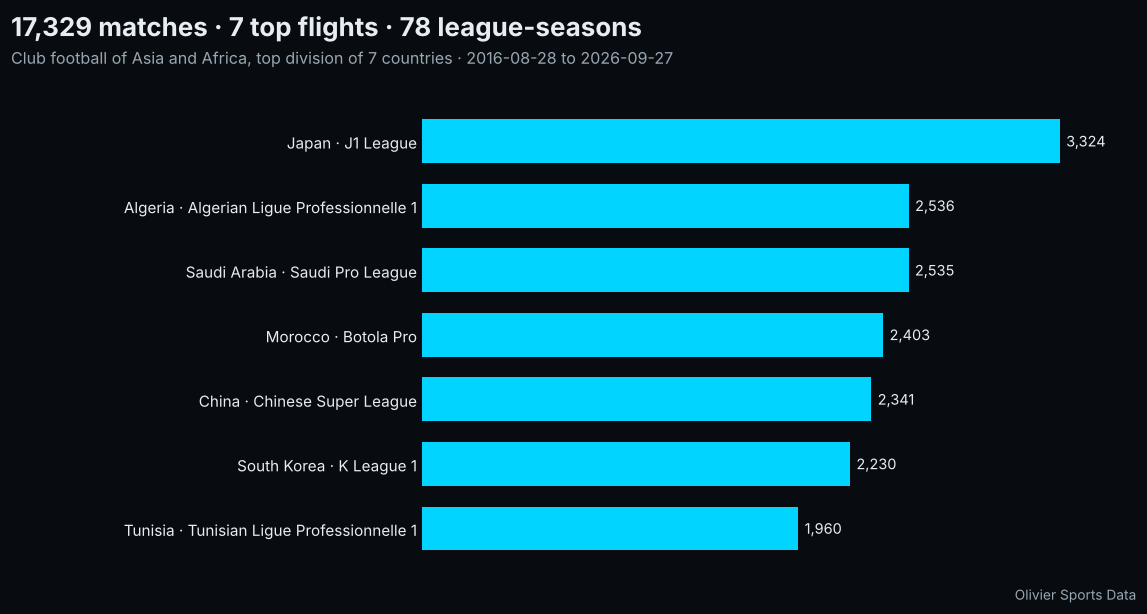

In [5]:
# matches per league (also saved as a PNG: Output tab on Kaggle)
names = M.drop_duplicates("Competition_Code").set_index("Competition_Code")
counts = M["Competition_Code"].value_counts().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(11, 5.6))
fig.subplots_adjust(left=0.36, right=0.95, top=0.83, bottom=0.06)
ax.barh(range(len(counts)), counts.values, height=0.68, color=CYAN, zorder=2)
ax.set_yticks(range(len(counts)), [f"{names.loc[c, 'Country']} · {names.loc[c, 'Competition']}" for c in counts.index],
              fontsize=10, color=FG)
for i, v in enumerate(counts.values):
    ax.text(v + counts.max() * 0.01, i, f"{v:,}", va="center", fontsize=9.5, color=FG)
ax.set_xlim(0, counts.max() * 1.12)
ax.xaxis.set_visible(False)
ax.grid(False)
ax.tick_params(axis="y", length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
fig.text(0.02, 0.93, f"{len(M):,} matches · {M['Competition_Code'].nunique()} top flights · {len(seasons)} league-seasons",
         fontsize=17, fontweight="bold", color=FG)
fig.text(0.02, 0.885, f"Club football of Asia and Africa, top division of 7 countries · "
         f"{M['Kickoff_UTC'].min()[:10]} to {M['Kickoff_UTC'].max()[:10]}", fontsize=10.5, color=FG2)
fig.text(0.95, 0.015, "Olivier Sports Data", ha="right", fontsize=9, color=FG2)
fig.savefig("matches_per_league.png", dpi=170, facecolor=BG)
plt.show()

## 4 · Opening and closing prices

One row per match. For each book and market: the first and the last valid pre-match quote, each with the time
it was recorded. The listing says a closing price is never an in-play price, so every closing time must sit
strictly before the scheduled kickoff.

In [6]:
head = pd.read_csv(os.path.join(ROOT, "AsiaAfrica_Opening_Closing_Odds.csv"), nrows=0).columns
OC = pd.read_csv(os.path.join(ROOT, "AsiaAfrica_Opening_Closing_Odds.csv"), low_memory=False,
                 dtype={c: str for c in head if c.endswith(("_Open_Time", "_Close_Time")) or c in ("Match_ID", "Season")})
check("one Opening_Closing row per match, same Match_IDs as Matches",
      len(OC) == len(M) and set(OC["Match_ID"]) == set(M["Match_ID"]))
kick = OC["Kickoff_Epoch"].astype("int64")
late, inverted, n_close = 0, 0, 0
for c in [c for c in OC.columns if c.endswith("_Close_Time")]:
    close = epoch(OC[c]); opened = epoch(OC[c.replace("_Close_", "_Open_")])
    n_close += close.notna().sum()
    late += (close >= kick).sum()
    inverted += (opened > close).sum()
check(f"all {n_close:,} closing times are before the scheduled kickoff", late == 0, f"{late} after")
check("opening time <= closing time everywhere", inverted == 0, f"{inverted} inverted")

cov = {b: int(OC[f"{b}_FT_1X2_Close_Time"].notna().sum()) for b in BOOKS}
check("matches with an FT 1X2 close, per book, as listed", cov == CLAIMS["ft_1x2_close_per_book"],
      " · ".join(f"{b} {n:,}" for b, n in cov.items()))
MARKETS8 = ["FT_1X2", "FT_Asian_Handicap", "FT_Total_Goals", "FT_Total_Corners", "HT_1X2", "HT_Asian_Handicap",
            "HT_Total_Goals", "HT_Total_Corners"]
first = {b: {m: OC.loc[OC[f"{b}_{m}_Close_Time"].notna(), "Kickoff_UTC"].min()[:10] for m in MARKETS8
             if f"{b}_{m}_Close_Time" in OC.columns and OC[f"{b}_{m}_Close_Time"].notna().sum() >= 100} for b in BOOKS}
check("markets priced by each book (closing price on at least 100 matches) and the first match of each, as listed",
      first == CLAIMS["first_close_per_market"],
      " · ".join(f"{b}: " + ", ".join(f"{m} {d}" for m, d in v.items()) for b, v in first.items()))

PASS  one Opening_Closing row per match, same Match_IDs as Matches


PASS  all 192,721 closing times are before the scheduled kickoff   [0 after]
PASS  opening time <= closing time everywhere   [0 inverted]
PASS  matches with an FT 1X2 close, per book, as listed   [Bet365 16,736 · Pinnacle 12,974 · Unibet 15,212 · Betfair 3,384 · Betsson 6,812]
PASS  markets priced by each book (closing price on at least 100 matches) and the first match of each, as listed   [Bet365: FT_1X2 2016-09-08, FT_Asian_Handicap 2016-09-08, FT_Total_Goals 2016-09-08, FT_Total_Corners 2019-10-13, HT_1X2 2018-01-11, HT_Asian_Handicap 2019-10-13, HT_Total_Goals 2016-12-10, HT_Total_Corners 2016-12-10 · Pinnacle: FT_1X2 2018-09-27, FT_Asian_Handicap 2023-06-23, FT_Total_Goals 2018-09-27 · Unibet: FT_1X2 2017-04-15, FT_Total_Goals 2017-04-15 · Betfair: FT_1X2 2023-11-03 · Betsson: FT_1X2 2022-07-03, FT_Total_Goals 2022-07-03]


### Coverage by league — share of matches with an FT 1X2 closing price

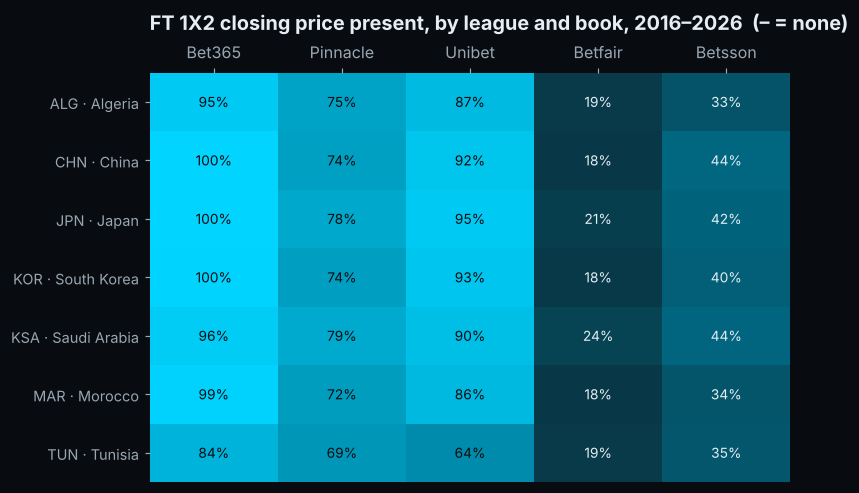

In [7]:
share = pd.DataFrame({b: OC.groupby("Competition_Code")[f"{b}_FT_1X2_Close_Time"].apply(lambda s: s.notna().mean())
                      for b in BOOKS}).reindex(ORDER)
cmap = LinearSegmentedColormap.from_list("cyan", ["#0d1b22", "#00708c", CYAN])
fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.imshow(share.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(BOOKS)), BOOKS)
ax.xaxis.tick_top()
ax.set_yticks(range(len(ORDER)), [f"{c} · {names.loc[c, 'Country']}" for c in ORDER], fontsize=9.5)
ax.grid(False)
for i, c in enumerate(ORDER):
    for j, b in enumerate(BOOKS):
        v = share.loc[c, b]
        ax.text(j, i, "–" if v == 0 else f"{v:.0%}", ha="center", va="center", fontsize=9,
                color="#080c10" if v > 0.6 else FG)
ax.set_title("FT 1X2 closing price present, by league and book, 2016–2026  (– = none)", pad=28)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### When is each book in the files?

The README's *Coverage over time* table, recomputed: the share of matches with an FT 1X2 closing price, month by
month, and the same for minute-by-minute statistics and events.
A gap is a month with at least 30 matches in which fewer than half of the matches have it, after the first month
that reaches one half. *Stops for*: a league with nothing after a date, at least 100 matches later.

PASS  first match with each book (FT 1X2 close), with minute stats and with events, as listed   [Bet365 2016-09-08 · Pinnacle 2018-09-27 · Unibet 2017-04-15 · Betfair 2023-11-03 · Betsson 2022-07-03 · Minute_Stats 2017-06-10 · Events 2016-08-28]
PASS  months with a gap, as listed   [Bet365 none · Pinnacle 2023-09..2023-11, 2026-07..2026-08 · Unibet 2026-07..2026-08 · Betfair 2024-11..2025-08, 2026-07..2026-08 · Betsson 2026-07..2026-08 · Minute_Stats 2018-01..2019-09, 2026-07 · Events none]
PASS  no league where a book, the minute stats or the events stop for good   [none]


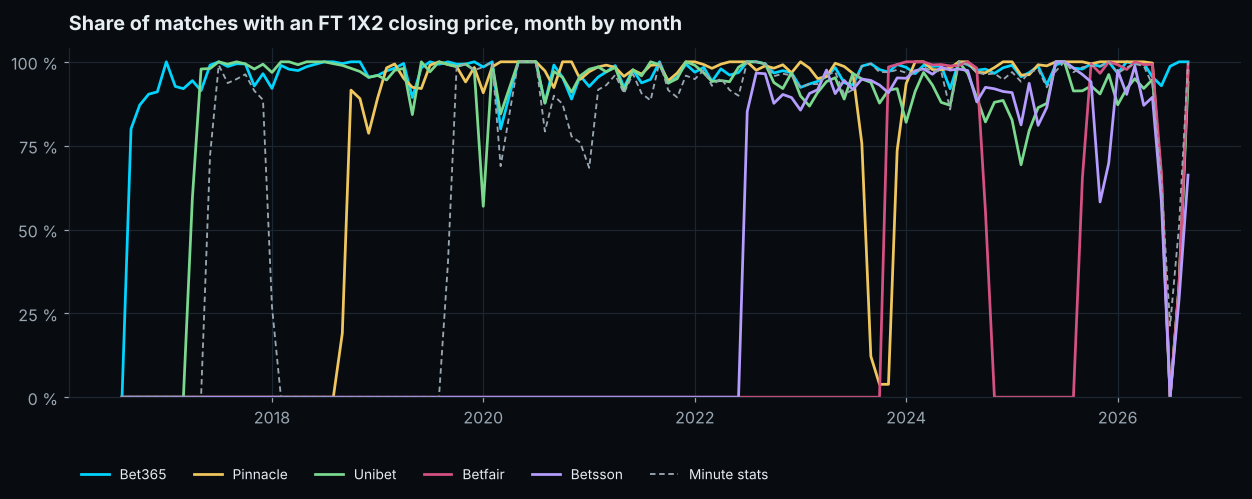

In [8]:
# the 5 books were collected for every league and season: the share is over all the matches
MI = M.set_index("Match_ID").reindex(OC["Match_ID"])
ev_ids = set()
for f in FILES["events"]:
    ev_ids |= set(pd.read_csv(f, usecols=["Match_ID"], dtype=str)["Match_ID"])
month = OC["Kickoff_UTC"].str[:7]
everywhere = np.ones(len(OC), bool)
series = {b: (OC[f"{b}_FT_1X2_Close_Time"].notna().to_numpy(), everywhere) for b in BOOKS}
series["Minute_Stats"] = (MI["Has_Minute_Stats"].to_numpy() == 1, everywhere)
series["Events"] = (OC["Match_ID"].isin(ev_ids).to_numpy(), everywhere)

def coverage_over_time(present, scope, threshold=0.5, min_matches=30, min_before=50, min_after=100):
    d = pd.DataFrame({"month": month[scope].to_numpy(), "ok": present[scope]})
    first = OC.loc[scope & present, "Kickoff_UTC"].min()[:10]
    g = d.groupby("month")["ok"].agg(["size", "mean"])
    states = [(m, r["mean"] >= threshold) for m, r in g.iterrows() if r["size"] >= min_matches]
    while states and not states[0][1]:
        states.pop(0)
    gaps, cur = [], None
    for m, ok in states:
        if not ok:
            cur = [m, m] if cur is None else [cur[0], m]
        elif cur:
            gaps.append(cur); cur = None
    if cur:
        gaps.append(cur)
    stops = {}
    for c in ORDER:
        mine = OC.loc[scope & (OC["Competition_Code"] == c).to_numpy()]
        hit = mine.loc[present[scope & (OC["Competition_Code"] == c).to_numpy()], "Kickoff_UTC"]
        if len(hit) >= min_before and (mine["Kickoff_UTC"] > hit.max()).sum() >= min_after:
            stops[c] = hit.max()[:10]
    return first, gaps, stops, g["mean"]

timeline, got_from, got_gaps, got_stops = {}, {}, {}, {}
for name, (present, scope) in series.items():
    got_from[name], got_gaps[name], got_stops[name], timeline[name] = coverage_over_time(present, scope)
check("first match with each book (FT 1X2 close), with minute stats and with events, as listed",
      got_from == CLAIMS["coverage_from"], " · ".join(f"{k} {v}" for k, v in got_from.items()))
check("months with a gap, as listed", got_gaps == CLAIMS["coverage_gaps"],
      " · ".join(f"{k} " + (", ".join(a if a == b else f"{a}..{b}" for a, b in v) or "none") for k, v in got_gaps.items()))
check("no league where a book, the minute stats or the events stop for good", got_stops == CLAIMS["coverage_stops"],
      " · ".join(f"{k} {v}" for k, v in got_stops.items() if v) or "none")

fig, ax = plt.subplots(figsize=(11.5, 4.8))
for name in BOOKS:
    s = timeline[name]
    ax.plot(pd.to_datetime(s.index), s.values, color=BOOK_COLOR[name], linewidth=1.8, label=name)
s = timeline["Minute_Stats"]
ax.plot(pd.to_datetime(s.index), s.values, color=FG2, linewidth=1.2, linestyle=(0, (3, 2)), label="Minute stats")
ax.set_ylim(0, 1.04)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0 %", "25 %", "50 %", "75 %", "100 %"])
ax.set_title("Share of matches with an FT 1X2 closing price, month by month", pad=12)
ax.legend(loc="lower left", ncol=6, fontsize=9, bbox_to_anchor=(0, -0.28))
plt.tight_layout(); plt.show()

### How close to kickoff is a "closing" price?

A closing quote is the last pre-match price the book published. Books update at different rhythms, so each one
gets its own closing time. Below: median and interquartile range of the gap to kickoff, FT 1X2.

PASS  median closing gap per book, as listed   [Pinnacle 4 min · Betfair 6 min · Betsson 10 min · Bet365 22 min · Unibet 1.8 h]


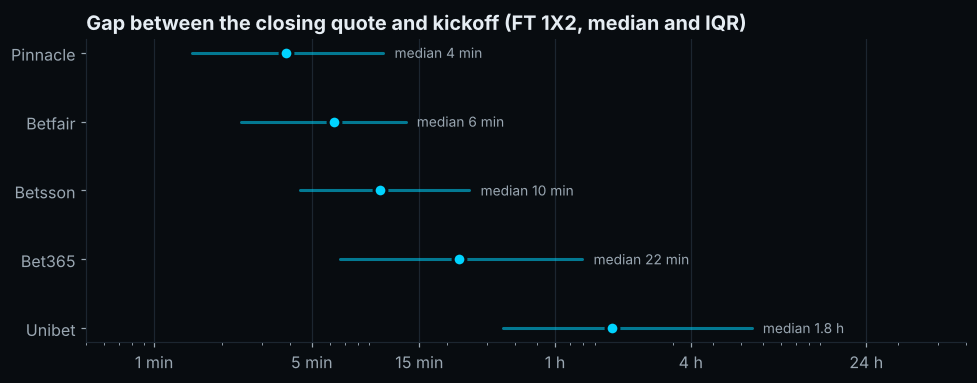

In [9]:
def upper_median(v):
    v = np.sort(np.asarray(v)); return v[len(v) // 2]

def readable(s):
    return f"{s / 3600:.1f} h" if s >= 5400 else f"{s / 60:.0f} min"

gaps = {}
for b in BOOKS:
    g = (kick - epoch(OC[f"{b}_FT_1X2_Close_Time"])).dropna().to_numpy()
    gaps[b] = g
got = {b: readable(upper_median(g)) for b, g in gaps.items()}
check("median closing gap per book, as listed", all(got[b] == CLAIMS["median_close_gap"][b] for b in BOOKS),
      " · ".join(f"{b} {got[b]}" for b in sorted(got, key=lambda b: upper_median(gaps[b]))))

books = sorted(BOOKS, key=lambda b: upper_median(gaps[b]), reverse=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, b in enumerate(books):
    q1, q2, q3 = np.percentile(gaps[b] / 60, [25, 50, 75])
    ax.plot([q1, q3], [i, i], color=CYAN, linewidth=2, solid_capstyle="round", alpha=0.55)
    ax.scatter([q2], [i], s=70, color=CYAN, zorder=3, edgecolor=BG, linewidth=2)
    ax.text(q3 * 1.12, i, f"median {readable(upper_median(gaps[b]))}", va="center", fontsize=9, color=FG2)
ax.set_xscale("log")
ax.set_xticks([1, 5, 15, 60, 240, 1440], ["1 min", "5 min", "15 min", "1 h", "4 h", "24 h"])
ax.set_yticks(range(len(books)), books)
ax.set_xlim(0.5, 4000)
ax.grid(axis="y", visible=False)
ax.set_title("Gap between the closing quote and kickoff (FT 1X2, median and IQR)")
plt.tight_layout(); plt.show()

### Are these real market prices?

A real closing line is better informed than the opening one: its implied probabilities should predict results
better. Probabilities are de-margined proportionally; lower log-loss is better. Compare open and close **within a
book** — books cover different sets of matches, so the rows are not comparable with each other.

In [10]:
y = OC["Result_90"].map({"H": 0, "D": 1, "A": 2}).to_numpy()
rows = []
for b in BOOKS:
    cols = lambda k: [f"{b}_FT_1X2_{k}_{s}" for s in ("Home", "Draw", "Away")]
    o, c = OC[cols("Open")].to_numpy(float), OC[cols("Close")].to_numpy(float)
    ok = ~np.isnan(o).any(1) & ~np.isnan(c).any(1)
    def logloss(x):
        p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
        return -np.log(p[np.arange(ok.sum()), y[ok]]).mean()
    rows.append((b, ok.sum(), logloss(o), logloss(c), (1 / o[ok]).sum(1).mean() - 1, (1 / c[ok]).sum(1).mean() - 1))
LL = pd.DataFrame(rows, columns=["Book", "Matches", "LogLoss open", "LogLoss close", "Margin open", "Margin close"]).set_index("Book")
check("closing beats opening on log-loss, for every book", (LL["LogLoss close"] < LL["LogLoss open"]).all())
LL.style.format({"Matches": "{:,}", "LogLoss open": "{:.4f}", "LogLoss close": "{:.4f}",
                 "Margin open": "{:.2%}", "Margin close": "{:.2%}"})

PASS  closing beats opening on log-loss, for every book


,Matches,LogLoss open,LogLoss close,Margin open,Margin close
Book,,,,,
Bet365,"16,736",1.0014,0.9863,9.42%,8.50%
Pinnacle,"12,974",0.9941,0.9818,6.94%,5.29%
Unibet,"15,212",0.9973,0.9892,9.75%,9.68%
Betfair,"3,384",1.0002,0.9830,9.01%,11.86%
Betsson,"6,812",0.9807,0.9717,8.30%,8.31%


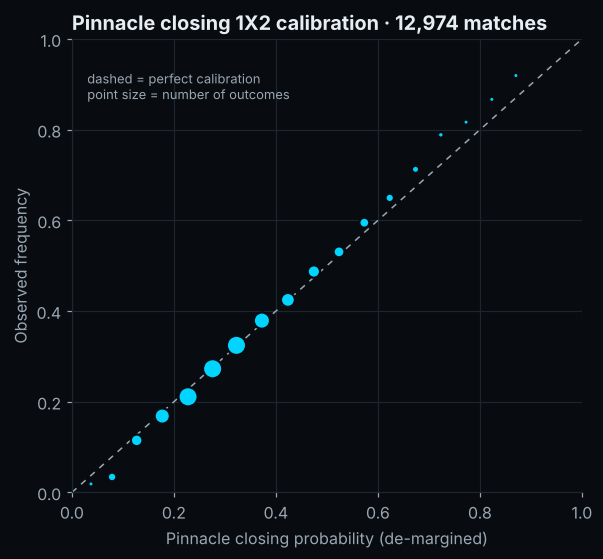

In [11]:
# Pinnacle closing 1X2: predicted probability vs observed frequency (all three outcomes pooled)
cols = [f"Pinnacle_FT_1X2_Close_{s}" for s in ("Home", "Draw", "Away")]
x = OC[cols].to_numpy(float); ok = ~np.isnan(x).any(1)
p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
hit = np.zeros_like(p); hit[np.arange(ok.sum()), y[ok]] = 1
cal = pd.DataFrame({"p": p.ravel(), "hit": hit.ravel()})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.05))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 50]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 30, 12, 160), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Pinnacle closing probability (de-margined)"); ax.set_ylabel("Observed frequency")
ax.set_title(f"Pinnacle closing 1X2 calibration · {ok.sum():,} matches")
ax.text(0.03, 0.93, "dashed = perfect calibration\npoint size = number of outcomes", fontsize=8.5, color=FG2, va="top")
plt.tight_layout(); plt.show()

## 5 · 31 million timestamped quotes

One pass over the 7 odds files, a few columns at a time. Checked on every row: a **pre-match** quote carries no
score and was recorded before the scheduled kickoff. The same pass reads the **real start** of each match from
Bet365's live clock (time of the quote minus its minute, minutes 1 to 15): `Kickoff_UTC` is the scheduled kickoff,
and a match often starts a few minutes after it.

In [12]:
kick_by_id = pd.Series(M["Kickoff_Epoch"].to_numpy("int64"), index=M["Match_ID"].astype("int64"))
comp_by_id = pd.Series(M["Competition_Code"].to_numpy(), index=M["Match_ID"].astype("int64"))
use = ["Match_ID", "Book", "Phase", "Epoch", "Minute", "Score_Home", "Score_Away"]

def read(path, cols):
    try:
        d = pd.read_csv(path, usecols=cols, engine="pyarrow")   # fast, multi-threaded
    except Exception:
        d = pd.read_csv(path, usecols=cols)
    for c in d.columns:   # the pyarrow reader turns ISO times into datetimes: show them as written in the file
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
    return d

t0 = time.time()
by_book_phase, by_book_league, starts, last_pre = [], [], [], []
ip_both, pre_clock, pre_clock_values = {}, {}, set()
pre_scored = pre_late = n_rows = 0
off_manifest = []
for f in FILES["odds"]:
    d = read(f, use)
    n_rows += len(d)
    if len(d) != ROWS.get(stem(f)):
        off_manifest.append(stem(f))
    pre = (d["Phase"] == "Pre-match").to_numpy()
    scored = d["Score_Home"].notna().to_numpy()
    pre_scored += (pre & scored).sum()
    pre_late += (pre & (d["Epoch"].to_numpy() >= kick_by_id.reindex(d["Match_ID"]).to_numpy())).sum()
    clock = d["Minute"].notna().to_numpy()
    both = ~pre & scored & d["Score_Away"].notna().to_numpy() & clock
    for b, n in d.loc[both, "Book"].value_counts().items():
        ip_both[b] = ip_both.get(b, 0) + int(n)
    for b, n in d.loc[pre & clock, "Book"].value_counts().items():
        pre_clock[b] = pre_clock.get(b, 0) + int(n)
    pre_clock_values |= set(d.loc[pre & clock, "Minute"].unique())
    by_book_phase.append(d.groupby(["Book", "Phase"]).size())
    by_book_league.append(d.groupby([d["Book"], comp_by_id.reindex(d["Match_ID"]).to_numpy()]).size())
    clock = d[(d["Book"] == "Bet365") & d["Score_Home"].notna() & d["Score_Away"].notna() & d["Minute"].between(1, 15)]
    starts.append((clock["Epoch"] - 60 * clock["Minute"]).groupby(clock["Match_ID"]).min())
    last_pre.append(d.loc[pre, "Epoch"].groupby(d.loc[pre, "Match_ID"]).max())
    print(f"{os.path.basename(f):42} {len(d):>12,} quotes   {time.time() - t0:5.0f} s")
    del d, clock

bp = pd.concat(by_book_phase).groupby(level=[0, 1]).sum().unstack(fill_value=0)
phase = bp.sum()
check(f"{CLAIMS['quotes']:,} quotes, every file equal to the MANIFEST", n_rows == CLAIMS["quotes"] and not off_manifest,
      f"{n_rows:,}" + (f", off: {', '.join(off_manifest)}" if off_manifest else ""))
check("in-play / pre-match split as listed",
      phase.get("In-play", 0) == CLAIMS["in_play"] and phase.get("Pre-match", 0) == CLAIMS["pre_match"],
      f"{phase.get('In-play', 0):,} in-play · {phase.get('Pre-match', 0):,} pre-match")
check("quotes per book as listed", {b: int(n) for b, n in bp.sum(axis=1).items()} == CLAIMS["quotes_per_book"])
check("no pre-match quote carries a score", pre_scored == 0, f"{pre_scored}")
check("every pre-match quote is before the scheduled kickoff", pre_late == 0, f"{pre_late}")
in_play_book = bp["In-play"] if "In-play" in bp.columns else pd.Series(dtype=int)
got_both = {b: ip_both.get(b, 0) for b in BOOKS}
check(f"score and clock on in-play quotes, book by book, as listed: {sum(got_both.values()) / phase.get('In-play', 1):.1%} of them carry both",
      got_both == CLAIMS["in_play_score_and_clock"],
      " · ".join(f"{b} {got_both[b] / in_play_book.get(b, 1):.1%}" if got_both[b] >= 0.001 * in_play_book.get(b, 1)
                 else f"{b} {got_both[b]} of {in_play_book.get(b, 0):,}" for b in BOOKS))
got_pre_clock = {b: pre_clock.get(b, 0) for b in BOOKS}
check("pre-match quotes carry no clock, except Bet365's minute 0 just before kickoff",
      got_pre_clock == CLAIMS["pre_match_with_minute"] and pre_clock_values <= {0},
      " · ".join(f"{b} {n}" for b, n in got_pre_clock.items() if n) + ", minute " + ", ".join(str(int(x)) for x in sorted(pre_clock_values)))
bp.assign(Total=bp.sum(axis=1)).reindex(BOOKS).style.format("{:,}")

AsiaAfrica_Odds_Timestamped_ALG.csv.gz        3,539,172 quotes       2 s


AsiaAfrica_Odds_Timestamped_CHN.csv.gz        5,281,092 quotes       6 s


AsiaAfrica_Odds_Timestamped_JPN.csv.gz        7,682,430 quotes      12 s


AsiaAfrica_Odds_Timestamped_KOR.csv.gz        4,739,091 quotes      16 s


AsiaAfrica_Odds_Timestamped_KSA.csv.gz        4,682,443 quotes      19 s


AsiaAfrica_Odds_Timestamped_MAR.csv.gz        3,641,143 quotes      22 s


AsiaAfrica_Odds_Timestamped_TUN.csv.gz        1,889,060 quotes      23 s
PASS  31,454,431 quotes, every file equal to the MANIFEST   [31,454,431]
PASS  in-play / pre-match split as listed   [24,380,334 in-play · 7,074,097 pre-match]
PASS  quotes per book as listed
PASS  no pre-match quote carries a score   [0]
PASS  every pre-match quote is before the scheduled kickoff   [0]
PASS  score and clock on in-play quotes, book by book, as listed: 94.5% of them carry both   [Bet365 98.9% · Pinnacle 25 of 79,247 · Unibet 99.6% · Betfair 18.5% · Betsson 99.0%]
PASS  pre-match quotes carry no clock, except Bet365's minute 0 just before kickoff   [Bet365 463, minute 0]


Phase,In-play,Pre-match,Total
Book,,,
Bet365,"20,588,980","2,075,468","22,664,448"
Pinnacle,"79,247","1,216,051","1,295,298"
Unibet,"1,971,588","103,676","2,075,264"
Betfair,"1,243,085","3,406,562","4,649,647"
Betsson,"497,434","272,340","769,774"


In [13]:
start = pd.concat(starts).groupby(level=0).min()                 # real start, Unix seconds (Bet365 live clock)
lastp = pd.concat(last_pre).groupby(level=0).max()               # last pre-match quote of the match, all books
late_min = (start - kick_by_id.reindex(start.index)) / 60        # real start minus scheduled kickoff, minutes
late = int(((late_min > 5) & (late_min <= 30)).sum())
check(f"on {CLAIMS['start_5_to_30_min_late']:,} of the {CLAIMS['matches_with_bet365_clock']:,} matches with a Bet365 live "
      "clock the real start is 5 to 30 minutes after the scheduled kickoff",
      late == CLAIMS["start_5_to_30_min_late"] and len(late_min) == CLAIMS["matches_with_bet365_clock"],
      f"{late:,}, median {late_min.median():.1f} min")
early = late_min[late_min < -180]
check(f"{CLAIMS['source_kickoff_over_3h_late']} matches whose kickoff in the source is more than 3 hours after the real start",
      len(early) == CLAIMS["source_kickoff_over_3h_late"],
      ", ".join(f"{i} {-v / 60:.0f} h" for i, v in early.sort_values().items()))
behind = late_min[late_min > 180]
check(f"{CLAIMS['source_kickoff_over_3h_early']} matches whose kickoff in the source is more than 3 hours before the real start",
      len(behind) == CLAIMS["source_kickoff_over_3h_early"],
      ", ".join(f"{i} {v / 60:.0f} h" for i, v in behind.sort_values().items()))
both = lastp.index.intersection(start.index)
check("no pre-match quote after the real start, on any match with a Bet365 live clock",
      (lastp[both] < start[both]).all(), f"{len(both):,} matches")
summary_late = pd.DataFrame({"league": comp_by_id.reindex(late_min.index), "late": late_min})
(summary_late.groupby("league")["late"]
    .agg(matches_with_clock="size", median_minutes="median",
         start_5_to_30_min_late=lambda s: f"{((s > 5) & (s <= 30)).mean():.0%}",
         start_before_schedule=lambda s: f"{(s < -1).mean():.0%}")
    .round({"median_minutes": 1}))

PASS  on 536 of the 16,216 matches with a Bet365 live clock the real start is 5 to 30 minutes after the scheduled kickoff   [536, median 0.8 min]
PASS  4 matches whose kickoff in the source is more than 3 hours after the real start   [9442668 22 h, 9621390 15 h, 9824934 11 h, 13048100 3 h]
PASS  5 matches whose kickoff in the source is more than 3 hours before the real start   [106161 5 h, 106165 6 h, 106167 6 h, 21288 14 h, 21437 17 h]
PASS  no pre-match quote after the real start, on any match with a Bet365 live clock   [16,181 matches]


,matches_with_clock,median_minutes,start_5_to_30_min_late,start_before_schedule
league,,,,
ALG,2310,1.2,9%,8%
CHN,2332,0.2,0%,0%
JPN,3318,3.3,3%,0%
KOR,2197,0.2,0%,0%
KSA,2204,0.2,1%,1%
MAR,2345,1.1,3%,3%
TUN,1510,1.3,8%,2%


Quotes per match, all markets, by league: how often each book updated its prices.

In [14]:
bl = pd.concat(by_book_league).groupby(level=[0, 1]).sum().unstack(level=0, fill_value=0).reindex(index=ORDER, columns=BOOKS)
matches_per_league = M.groupby("Competition_Code").size()
(bl.div(matches_per_league, axis=0)).round(0).astype(int).rename_axis("Quotes per match").style.format("{:,}")

Book,Bet365,Pinnacle,Unibet,Betfair,Betsson
Quotes per match,,,,,
ALG,"1,054",47,100,164,31
CHN,"1,593",110,153,336,64
JPN,"1,597",98,154,406,57
KOR,"1,480",96,137,360,52
KSA,"1,297",75,115,315,46
MAR,"1,211",49,103,121,32
TUN,744,37,56,105,22


### 37 more bookmakers: dated snapshots

`Bookmaker_Snapshots` holds the first price the source kept for each other bookmaker (`Open`) and its latest
snapshot that is still pre-match (`Last_Pre_Match`). A dated snapshot, not a closing price: the minutes before
kickoff are given on every row.

In [15]:
ids = set(M["Match_ID"].astype("int64"))
parts, off = [], []
for f in FILES["snapshots"]:
    d = read(f, ["Match_ID", "Book", "Market", "Snapshot", "Minutes_Before_Kickoff"])
    if len(d) != ROWS.get(stem(f)):
        off.append(stem(f))
    parts.append(d)
S = pd.concat(parts, ignore_index=True); del parts
check(f"{CLAIMS['snapshots']:,} snapshot rows, all joined to a match", len(S) == CLAIMS["snapshots"] and S["Match_ID"].isin(ids).all()
      and not off, f"{len(S):,}" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))
check(f"{CLAIMS['snapshot_books']} bookmakers, none of the 5 main books",
      S["Book"].nunique() == CLAIMS["snapshot_books"] and not set(S["Book"]) & set(BOOKS + ["Betfair (Sportsbook)"]),
      f"{S['Book'].nunique()} books")
per_match = S.groupby("Match_ID")["Book"].nunique()
check(f"{CLAIMS['snapshot_matches']:,} matches with snapshots, {CLAIMS['snapshot_books_per_match']} bookmakers per match "
      "on average", len(per_match) == CLAIMS["snapshot_matches"]
      and round(per_match.mean(), 1) == CLAIMS["snapshot_books_per_match"], f"{len(per_match):,}, {per_match.mean():.1f}")
check("every snapshot is pre-match (Minutes_Before_Kickoff >= 0)", (S["Minutes_Before_Kickoff"] >= 0).all())
last = S[S["Snapshot"] == "Last_Pre_Match"]
print(f"{S['Match_ID'].nunique():,} matches, {S.groupby('Match_ID')['Book'].nunique().mean():.1f} bookmakers per match on average")
(last.groupby("Market")["Minutes_Before_Kickoff"]
     .agg(rows="size", median_minutes_before_kickoff="median",
          within_60_min=lambda s: f"{(s <= 60).mean():.0%}", over_24_h=lambda s: f"{(s > 1440).mean():.0%}"))

PASS  944,160 snapshot rows, all joined to a match   [944,160]


PASS  37 bookmakers, none of the 5 main books   [37 books]
PASS  16,644 matches with snapshots, 13.8 bookmakers per match on average   [16,644, 13.8]
PASS  every snapshot is pre-match (Minutes_Before_Kickoff >= 0)
16,644 matches, 13.8 bookmakers per match on average


,rows,median_minutes_before_kickoff,within_60_min,over_24_h
Market,,,,
FT_1X2,224600,78.0,48%,23%
FT_Asian_Handicap,95216,148.0,46%,27%
FT_Total_Goals,152344,115.0,45%,25%


### Lineups, events, minute-by-minute stats

Rows counted from the files themselves, and every row must join a match of `AsiaAfrica_Matches` on `Match_ID`.
The Algeria, Morocco and Tunisia lineup files hold only their header: the source has no lineups for these three leagues.

In [16]:
timed, untimed, rows_untimed, event_types = set(), set(), 0, set()
for folder, claim in (("lineups", "lineups"), ("events", "events"), ("minute_stats", "minute_stats")):
    n, orphans, off = 0, 0, []
    for f in FILES[folder]:
        d = read(f, {"minute_stats": ["Match_ID", "Timestamp_UTC"], "events": ["Match_ID", "Event_Type"]}.get(folder, ["Match_ID"]))
        if folder == "events":
            event_types |= set(d["Event_Type"].dropna())
        if folder == "minute_stats":
            has = d["Timestamp_UTC"].notna()
            timed |= set(d.loc[has, "Match_ID"]); untimed |= set(d.loc[~has, "Match_ID"])
            rows_untimed += int((~has).sum())
        n += len(d)
        orphans += (~d["Match_ID"].isin(ids)).sum()
        if len(d) != ROWS.get(stem(f)):
            off.append(stem(f))
    check(f"{CLAIMS[claim]:,} {folder.replace('_', ' ')} rows, all joined to a match", n == CLAIMS[claim] and orphans == 0 and not off,
          f"{n:,} rows, {orphans} without a match" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))
kick_utc = M.set_index(M["Match_ID"].astype("int64"))["Kickoff_UTC"]
first_timed = kick_utc.reindex(list(timed)).min()
check(f"{CLAIMS['event_types']} event types", len(event_types) == CLAIMS["event_types"], ", ".join(sorted(event_types)))
share = (M.groupby("Competition_Code")["Has_Lineups"].mean() * 100).round().astype(int).to_dict()
check("share of matches with both starting elevens, per league, as listed", share == CLAIMS["lineups_share"],
      " · ".join(f"{c} {v} %" for c, v in share.items()))
T = CLAIMS["minute_stats_time"]
check(f"minute-by-minute statistics carry their recording time from {T['from']}, never before, always after",
      first_timed[:10] == T["from"] and not (timed & untimed) and kick_utc.reindex(list(untimed)).max() < first_timed
      and len(untimed) == T["matches_without"] and rows_untimed == T["rows_without"],
      f"first {first_timed[:10]}; {len(untimed):,} matches and {rows_untimed:,} rows without time")

PASS  325,517 lineups rows, all joined to a match   [325,517 rows, 0 without a match]


PASS  390,628 events rows, all joined to a match   [390,628 rows, 0 without a match]


PASS  4,287,131 minute stats rows, all joined to a match   [4,287,131 rows, 0 without a match]
PASS  13 event types   [Assist, Corner, Goal, Missed Penalty, Offside, Penalty Shootout Missed, Penalty Shootout Scored, Race To Corners, Red Card, Shot Off Target, Shot On Target, Substitution, Yellow Card]
PASS  share of matches with both starting elevens, per league, as listed   [ALG 0 % · CHN 100 % · JPN 100 % · KOR 67 % · KSA 48 % · MAR 0 % · TUN 0 %]
PASS  minute-by-minute statistics carry their recording time from 2021-05-10, never before, always after   [first 2021-05-10; 3,127 matches and 1,131,216 rows without time]


## 6 · One match, quote by quote

The match shown in the listing: Avispa Fukuoka 2-2 Gamba Osaka, J1 100 Year Vision League, group
stage, 21 March 2026. Gamba led twice (11' and 42'), Avispa missed a penalty at 81' and equalised in added time
(90+3'); in this format a draw after 90 minutes goes straight to penalties, and Avispa won the shoot-out
14-13. Bet365 full-time 1X2 in play, recomputed here from `AsiaAfrica_Odds_Timestamped_JPN.csv.gz`,
then drawn as implied probabilities, with the goals and the missed penalty of the events table on top. The events
table and Bet365's clock count minutes each in their own way (the equaliser is 90+3' in the events, minute 92 on
Bet365's clock): clocks are delivered as the bookmaker sent them, never adjusted.

In [17]:
MID = 11248363
row = M[M["Match_ID"] == str(MID)].iloc[0]
check("the Matches row: Avispa Fukuoka 1-2 at half-time, 2-2 after 90 minutes, no extra time, shoot-out 14-13, group stage, "
      "home ground",
      (row["Home_Goals_HT"], row["Away_Goals_HT"], row["Home_Goals_90"], row["Away_Goals_90"], row["Home_Penalties"],
       row["Away_Penalties"], row["Extra_Time"], row["Stage"], row["Neutral_Venue"])
      == (1, 2, 2, 2, 14, 13, 0, "Group Stage", 0))
cols = ["Match_ID", "Book", "Market", "Phase", "Timestamp_UTC", "Epoch", "Minute",
        "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]
jpn_odds = read(next(f for f in FILES["odds"] if stem(f).endswith("_JPN")), cols)
one = jpn_odds[jpn_odds["Match_ID"] == MID]
del jpn_odds
print(one.groupby(["Book", "Phase"]).size().unstack(fill_value=0))
t = one[(one["Book"] == "Bet365") & (one["Market"] == "FT_1X2") & (one["Phase"] == "In-play")].sort_values("Epoch", kind="stable")
t = t.reset_index(drop=True)
check(f"{CLAIMS['example_quotes_all_books']:,} quotes from the 5 books on this match",
      len(one) == CLAIMS["example_quotes_all_books"], f"{len(one):,}")
check(f"{CLAIMS['example_in_play_bet365_1x2']} in-play Bet365 1X2 quotes on this match",
      len(t) == CLAIMS["example_in_play_bet365_1x2"], f"{len(t)}")
real = start[MID]
pre = one[one["Phase"] == "Pre-match"]
check("scheduled at " + row["Kickoff_UTC"][11:16] + " UTC, real start "
      + pd.Timestamp(real, unit="s").strftime("%H:%M:%S") + " (Bet365 clock): every pre-match quote is before the "
      "scheduled kickoff, the first in-play quote after the real start",
      (pre["Epoch"] < row["Kickoff_Epoch"]).all() and t["Epoch"].iloc[0] > real)

# the listing's rule: around each score change, the quote before and the quote at the change
keep, last = [], None
for i, sc in enumerate(zip(t["Score_Home"].fillna(-1), t["Score_Away"].fillna(-1))):
    if sc != last:
        keep += [k for k in (i - 1, i) if k >= 0 and k not in keep]
        last = sc
show = (t.loc[keep, ["Timestamp_UTC", "Minute", "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]]
          .astype({"Minute": "Int64", "Score_Home": "Int64", "Score_Away": "Int64"}))
show

PASS  the Matches row: Avispa Fukuoka 1-2 at half-time, 2-2 after 90 minutes, no extra time, shoot-out 14-13, group stage, home ground


Phase     In-play  Pre-match
Book                        
Bet365       1107        101
Betfair       168          9
Betsson       103         11
Pinnacle        0        115
Unibet        232         12
PASS  1,858 quotes from the 5 books on this match   [1,858]
PASS  157 in-play Bet365 1X2 quotes on this match   [157]
PASS  scheduled at 05:30 UTC, real start 05:35:03 (Bet365 clock): every pre-match quote is before the scheduled kickoff, the first in-play quote after the real start


,Timestamp_UTC,Minute,Score_Home,Score_Away,Price_Home,Price_Draw,Price_Away,Suspended
0,2026-03-21T05:36:47Z,1,0,0,4.00,3.250,1.952,0
14,2026-03-21T05:45:51Z,10,0,0,3.60,3.000,2.200,0
15,2026-03-21T05:46:15Z,11,0,1,8.50,4.333,1.400,0
29,2026-03-21T05:55:51Z,20,0,1,9.00,4.000,1.400,0
30,2026-03-21T05:56:16Z,21,1,1,3.50,2.750,2.375,0
57,2026-03-21T06:16:45Z,41,1,1,3.75,2.400,2.600,0
58,2026-03-21T06:17:05Z,42,1,2,11.00,4.333,1.363,0
148,2026-03-21T07:24:26Z,91,1,2,101.00,8.000,1.083,0
149,2026-03-21T07:25:11Z,92,2,2,13.00,1.090,15.000,0
152,2026-03-21T07:26:03Z,92,2,2,15.00,1.062,17.000,0


 Minute  Added_Time     Event_Type Team_Side
   11.0         NaN           Goal      Away
   22.0         NaN           Goal      Home
   42.0         NaN           Goal      Away
   81.0         NaN Missed Penalty      Home
   90.0         3.0           Goal      Home


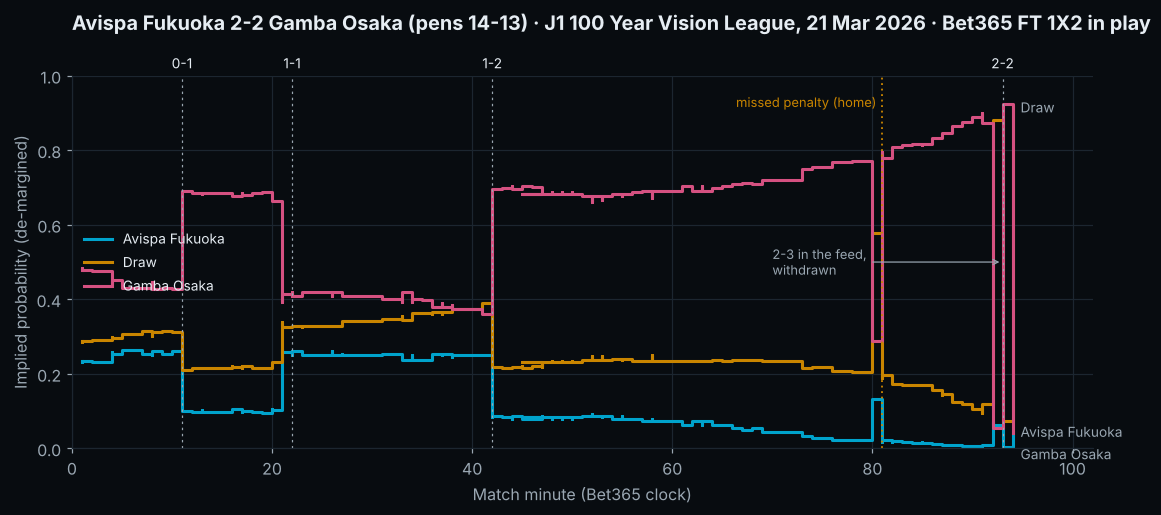

In [18]:
ev = read(next(f for f in FILES["events"] if stem(f).endswith("_JPN")),
          ["Match_ID", "Minute", "Added_Time", "Event_Type", "Team_Side", "Player"])
mine = ev[(ev["Match_ID"] == MID)]
goals = mine[mine["Event_Type"] == "Goal"].sort_values(["Minute", "Added_Time"], na_position="first")
missed = mine[mine["Event_Type"] == "Missed Penalty"]
print(pd.concat([goals, missed]).sort_values(["Minute", "Added_Time"], na_position="first")
      [["Minute", "Added_Time", "Event_Type", "Team_Side"]].to_string(index=False))

live = t[(t["Suspended"] == 0) & t["Minute"].notna()].copy()
inv = 1 / live[["Price_Home", "Price_Draw", "Price_Away"]]
prob = inv.div(inv.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = live["Minute"]
names_hda = {"Price_Home": "Avispa Fukuoka", "Price_Draw": "Draw", "Price_Away": "Gamba Osaka"}
for col, side in zip(prob.columns, ["Home", "Draw", "Away"]):
    ax.plot(x, prob[col], color=HDA[side], linewidth=2, label=names_hda[col], drawstyle="steps-post")
ends = sorted(((prob[col].iloc[-1], col) for col in prob.columns), reverse=True)
y_lab = []
for v, col in ends:                                   # end labels kept at least 0.06 apart
    y_lab.append(min(v, y_lab[-1] - 0.06) if y_lab else v)
    ax.text(x.iloc[-1] + 0.8, y_lab[-1], names_hda[col], color=FG2, fontsize=9, va="center")
score_h = score_a = 0
previous, level = -99, 0
for _, g in goals.iterrows():
    m = g["Minute"] + (0 if pd.isna(g["Added_Time"]) else g["Added_Time"])
    score_h += g["Team_Side"] == "Home"; score_a += g["Team_Side"] == "Away"
    level = 1 - level if m - previous < 5 else 0          # stagger labels of goals close together
    previous = m
    ax.axvline(m, color=FG2, linewidth=0.8, linestyle=(0, (2, 3)))
    ax.text(m, 1.02 + 0.06 * level, f"{score_h}-{score_a}", ha="center", fontsize=9, color=FG,
            transform=ax.get_xaxis_transform())
for _, g in missed.iterrows():
    ax.axvline(g["Minute"], color=HDA["Draw"], linewidth=1.2, linestyle=(0, (1, 2)))
    ax.text(g["Minute"] - 0.6, 0.95, f"missed penalty ({g['Team_Side'].lower()})", fontsize=8.5, color=HDA["Draw"],
            transform=ax.get_xaxis_transform(), va="top", ha="right")
flicker = live[(live["Score_Home"] == 2) & (live["Score_Away"] == 3)]     # a 2-3 sent with the quotes, then withdrawn
if len(flicker):
    ax.annotate("2-3 in the feed,\nwithdrawn", xy=(flicker["Minute"].iloc[0], 0.5), xytext=(70, 0.5),
                fontsize=8.5, color=FG2, va="center", arrowprops=dict(arrowstyle="->", color=FG2, lw=0.8))
ax.set_ylim(0, 1); ax.set_xlim(0, max(97, x.max() + 8))
ax.set_xlabel("Match minute (Bet365 clock)"); ax.set_ylabel("Implied probability (de-margined)")
ax.set_title("Avispa Fukuoka 2-2 Gamba Osaka (pens 14-13) · J1 100 Year Vision League, 21 Mar 2026 · Bet365 FT 1X2 in play",
             pad=30)
ax.legend(loc="center left", fontsize=9)
plt.tight_layout(); plt.show()

## 7 · Nothing a spreadsheet can reinterpret

Formations are digits (4231 = 4-2-3-1), timestamps carry the T and the Z, seasons read 2016/17 or 2019, and no
text cell starts with a character a spreadsheet would read as a formula or turn into a date.

In [19]:
iso = re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z$")
risky = re.compile(r"^([=+@\-]|\d{1,2}[-/]\d{1,2}([-/]\d{2,4})?$|\d{1,2}:\d{2}(:\d{2})?$)")
form = pd.concat([M["Home_Formation"], M["Away_Formation"]]).dropna()
check("formations are digits that add up to 10 players",
      form.str.fullmatch(r"\d{3,5}").all() and form.map(lambda s: sum(map(int, s)) == 10).all(),
      f"{len(form):,} formations, e.g. {form.value_counts().index[0]}")
times = pd.concat([M["Kickoff_UTC"]] + [OC[c].dropna() for c in OC.columns if c.endswith(("_Open_Time", "_Close_Time"))])
check("every timestamp is ISO 8601 with T and Z", times.map(lambda s: bool(iso.match(s))).all(), f"{len(times):,} cells")
TS = pd.read_csv(os.path.join(ROOT, "AsiaAfrica_Team_Stats.csv"), dtype=str)
is_text = lambda s: s.dtype == object or isinstance(s.dtype, pd.StringDtype)
text_cells = pd.concat([df[c].dropna().astype(str) for df in (M, OC, TS) for c in df.columns if is_text(df[c])
                        and not c.endswith(("_Open_Time", "_Close_Time", "_UTC"))])
bad = text_cells[text_cells.map(lambda s: bool(risky.match(s)))]
check("no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)", bad.empty,
      f"{len(text_cells):,} text cells" + (f", e.g. {bad.iloc[0]!r}" if len(bad) else ""))
check(f"{CLAIMS['team_stats']:,} team-stat rows, two per match", len(TS) == CLAIMS["team_stats"] == 2 * len(M))
check(f"{CLAIMS['team_stat_metrics']} team statistics per row", TS.shape[1] - 4 == CLAIMS["team_stat_metrics"],
      f"{TS.shape[1] - 4}")

PASS  formations are digits that add up to 10 players   [11,244 formations, e.g. 442]


PASS  every timestamp is ISO 8601 with T and Z   [402,771 cells]


PASS  no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)   [1,292,236 text cells]
PASS  34,658 team-stat rows, two per match
PASS  29 team statistics per row   [29]


## 8 · Summary

In [20]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

57 / 57 claims verified


Result,Claim,Detail
PASS,all 44 files present,
PASS,every SHA-256 matches the MANIFEST,
PASS,"17,329 matches","17,329"
PASS,Match_ID is unique,
PASS,none of the 31 removed source events is in the files; the 4 matches decided by the federation and kept are,
PASS,"7 top flights (club football, division 1), 78 league-seasons, 78 editions (Japan's 2026 special tournament counts as its own season)",7 / 78 / 78
PASS,"matches per league, as listed",
PASS,"first kickoff on 2016-08-28, last before 2026-10-01",2016-08-28T10:00:00Z to 2026-09-27T20:00:00Z
PASS,Season reads 2016/17 (two calendar years) or 2019 (one),"2016, 2016/17, 2017, 2017/18..."
PASS,Leg only in knockout stages,


---

Everything above ran on the files a buyer downloads. The README in the ZIP holds the full column dictionary,
the seasons, tournaments and stages of every league, the coverage tables (by league, by book, over time), the
removed source events with their evidence, and every known limitation.

👉 ⚽ **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/gxvqou?utm_source=github&utm_medium=notebook&utm_campaign=asia_africa_premium&utm_content=notebook_bottom)** 👈

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*